# 01 — EDA e bootstrap: sinistros de trânsito do Recife (2015–2024)

Análise exploratória da base que alimenta o modelo de risco por local
(`ARCHITECTURE.md`, seções 2 e 3). Fonte: Portal de Dados Abertos do Recife, dataset
`acidentes-de-transito-com-e-sem-vitimas` (CKAN, licença ODbL), 10 CSVs anuais.

O notebook roda dentro do Docker, depois do pipeline de preparo:

```
docker compose run --rm tooling python -m src.ingestao.fetch_datasets
docker compose run --rm tooling python -m src.preparo.clean_sinistros
docker compose run --rm tooling python -m src.preparo.local_id
docker compose run --rm tooling python -m src.preparo.features
docker compose --profile dev up jupyter
```

Ordem (seção 13 do `ARCHITECTURE.md`): carga, estatísticas descritivas, nulos e duplicados,
log de colunas por ano, proporção de acidentes com vítima, distribuição dos alvos, as
visualizações com interpretação, as decisões de tratamento e as ressalvas.

## 1. Carga

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160, "display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})

# O notebook roda de notebooks/ (Jupyter ou nbconvert); os dados ficam em ../data.
RAIZ = Path.cwd().parent if (Path.cwd().parent / "data").exists() else Path("/app")
PROC = RAIZ / "data" / "processed"

sinistros = pd.read_parquet(PROC / "sinistros" / "sinistros_2015_2024.parquet")
acidentes = pd.read_parquet(PROC / "acidentes_local.parquet")
features = pd.read_parquet(PROC / "features.parquet")
colunas_por_ano = json.loads((PROC / "sinistros" / "colunas_por_ano.json").read_text(encoding="utf-8"))
resumo_local = json.loads((PROC / "local_id_resumo.json").read_text(encoding="utf-8"))

for nome, df in [("sinistros (limpo)", sinistros), ("acidentes (que contam, com local)", acidentes),
                 ("features (local × trimestre)", features)]:
    print(f"{nome:36s} {df.shape[0]:>7,} linhas × {df.shape[1]} colunas")

sinistros (limpo)                     72,253 linhas × 53 colunas
acidentes (que contam, com local)     60,203 linhas × 59 colunas
features (local × trimestre)          65,247 linhas × 58 colunas


Três tabelas, cada uma um passo do pipeline: `sinistros` é a saída da limpeza (uma linha por
chamado, inclusive cancelados e duplicidades, com a coluna `situacao`); `acidentes` tira o que
não conta como acidente e acrescenta `local_id` e `trimestre`; `features` é o painel
local × trimestre usado pelo modelo.

## 2. Estatísticas descritivas

In [2]:
por_ano = sinistros.groupby("ano_arquivo").agg(
    chamados=("ano_arquivo", "size"),
    com_vitima=("gravidade", lambda s: s.isin(["COM VÍTIMA", "VÍTIMA FATAL"]).sum()),
    vitimas=("vitimas", "sum"),
    vitimas_fatais=("vitimasfatais", "sum"),
    atropelamentos=("atropelamento", "sum"),
)
por_ano

,chamados,com_vitima,vitimas,vitimas_fatais,atropelamentos
ano_arquivo,,,,,
2015,7273,1420,1624,0,165
2016,11263,2185,2552,39,255
2017,11757,2192,2626,38,274
2018,11411,2059,2397,28,219
2019,12062,2260,2593,25,250
2020,4092,1774,2089,20,148
2021,2379,1834,2123,25,163
2022,2669,2103,2460,25,203
2023,4032,3431,3878,31,212


In [3]:
contagens = ["auto", "moto", "ciclom", "ciclista", "pedestre", "onibus", "caminhao", "vitimas", "vitimasfatais"]
sinistros[contagens].astype("float").describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
auto,72253.0,1.27,0.80,0.0,1.0,1.0,2.0,9.0
moto,72253.0,0.36,0.53,0.0,0.0,0.0,1.0,4.0
ciclom,72253.0,0.01,0.08,0.0,0.0,0.0,0.0,2.0
ciclista,72253.0,0.02,0.14,0.0,0.0,0.0,0.0,5.0
pedestre,72253.0,0.03,0.18,0.0,0.0,0.0,0.0,5.0
onibus,72253.0,0.14,1.54,0.0,0.0,0.0,0.0,404.0
caminhao,72253.0,0.09,0.29,0.0,0.0,0.0,0.0,4.0
vitimas,72253.0,0.38,0.61,0.0,0.0,0.0,1.0,24.0
vitimasfatais,64980.0,0.00,0.07,0.0,0.0,0.0,0.0,6.0


As colunas de envolvidos contam **participantes**, não vítimas. A mediana de autos é 1 e a das
demais categorias é 0: a maioria dos sinistros tem um ou dois veículos. O máximo de vítimas
num chamado passa de 10 (ônibus), o que puxa a média para cima; por isso o tratamento usa
mediana para nulos numéricos (seção 8).

## 3. Nulos e duplicados

In [4]:
import sys
sys.path.insert(0, str(RAIZ))
from src.preparo.clean_sinistros import RAW_DIR, load_year, normalizar_schema

bruto, _ = normalizar_schema(dict(load_year(p) for p in sorted(RAW_DIR.glob("*.csv"))))
duplicados = bruto.duplicated().groupby(bruto["ano_arquivo"]).sum()
print("duplicados exatos removidos na limpeza:", duplicados[duplicados > 0].to_dict(), "| total:", int(duplicados.sum()))
print("situacao:", sinistros["situacao"].value_counts().head(6).to_dict())
print("exclusões no preparo do local:", resumo_local["exclusoes"])

duplicados exatos removidos na limpeza: {2017: 1, 2021: 1} | total: 2
situacao: {'FINALIZADA': 59006, 'CANCELADA': 11563, 'EM ATENDIMENTO': 576, 'DUPLICIDADE': 455, 'PENDENTE': 426, 'EQUIPE EM DESLOCAMENTO': 122}
exclusões no preparo do local: {'situacao_excluida': {'CANCELADA': 11563, 'DUPLICIDADE': 455}, 'data_fora_do_ano_arquivo': 32, 'sem_bairro_ou_logradouro': 393}


In [5]:
colunas_nulos = ["hora", "bairro", "endereco", "endereco_cruzamento", "acidente_verificado",
                 "tempo_clima", "sinalizacao", "velocidade_max_via", "vitimasfatais", "num_semaforo"]
nulos = sinistros[colunas_nulos].copy()
nulos["acidente_verificado"] = nulos["acidente_verificado"].astype("object").mask(nulos["acidente_verificado"] == "DESCONHECIDO")
(nulos.isna().groupby(sinistros["ano_arquivo"]).mean() * 100).round(0).astype(int)

,hora,bairro,endereco,endereco_cruzamento,acidente_verificado,tempo_clima,sinalizacao,velocidade_max_via,vitimasfatais,num_semaforo
ano_arquivo,,,,,,,,,,
2015,0,1,1,100,100,100,100,100,100,100
2016,0,1,1,0,100,100,100,100,0,100
2017,0,0,0,0,100,100,100,100,0,100
2018,0,0,0,0,83,84,84,95,0,94
2019,0,1,0,0,24,20,21,76,0,75
2020,0,1,0,100,20,17,19,73,0,72
2021,0,0,0,100,25,25,26,72,0,74
2022,100,0,0,100,22,21,22,71,0,76
2023,0,0,0,100,100,100,100,100,0,92


Os nulos não são aleatórios: são **colunas que mudam de formulário com o tempo**. `hora` é 100%
nula em 2022 (o arquivo inteiro veio sem hora; a Tarefa 0 verificou que não há outra coluna
com o horário). `endereco_cruzamento` só existe de 2016 a 2019, `acidente_verificado` só de
2018 em diante, e as colunas de contexto da via (`tempo_clima`, `sinalizacao`...) só são
preenchidas de 2018 a 2022. `vitimasfatais` não existe em 2015. Os duplicados exatos são só
2 em 72 mil chamados; o que pesa são os 11.563 chamados `CANCELADA` e os 455 `DUPLICIDADE`,
que ficam fora de toda contagem.

## 4. Log de colunas por ano

cabeçalhos com nome diferente do padrão: {'2018': ['DATA'], '2019': ['DATA'], '2022': ['Protocolo'], '2023': ['Protocolo'], '2024': ['Protocolo']}


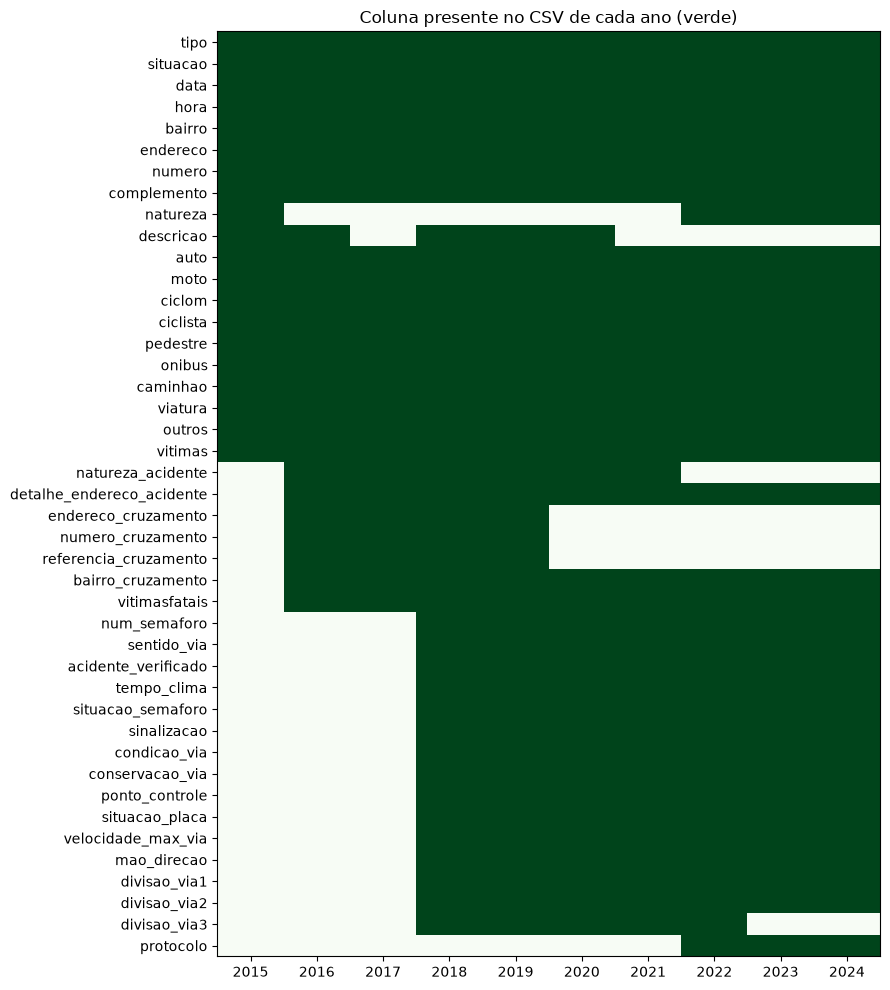

In [6]:
presenca = pd.DataFrame({ano: {c.lower(): 1 for c in cols} for ano, cols in colunas_por_ano.items()}).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(9, 10))
ax.imshow(presenca.values, aspect="auto", cmap="Greens")
ax.set(xticks=range(presenca.shape[1]), xticklabels=presenca.columns, yticks=range(presenca.shape[0]),
       yticklabels=presenca.index, title="Coluna presente no CSV de cada ano (verde)")
ax.grid(False)
plt.tight_layout()
print("cabeçalhos com nome diferente do padrão:", {a: [c for c in cols if c != c.lower()] for a, cols in colunas_por_ano.items() if any(c != c.lower() for c in cols)})

O log de colunas, salvo pela etapa `normalizar_schema` em `colunas_por_ano.json`, confirma o
diagnóstico: a coluna `timestamp` do dicionário do portal **não existe** em nenhum ano; o nome
real é `data`, escrito `DATA` em 2018 e 2019. `Protocolo` só aparece de 2022 em diante. A
normalização (minúsculas, sem acento, sem espaço) resolve as grafias, e uma coluna ausente num
ano vira nulo nas linhas daquele ano.

## 5. Proporção de acidentes com vítima por ano e por trimestre

trimestre,2019Q3,2019Q4,2020Q1,2020Q2,2020Q3,2020Q4,2021Q1,2021Q2
proporcao_com_vitima,0.21,0.198,0.22,0.724,0.779,0.826,0.768,0.751


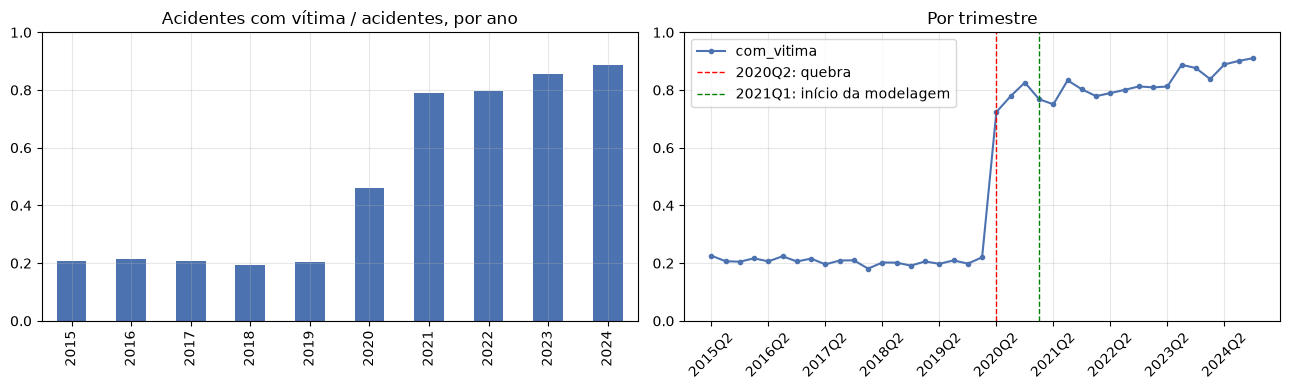

In [7]:
prop_ano = acidentes.groupby(acidentes["data"].dt.year)["com_vitima"].mean()
prop_tri = acidentes.groupby("trimestre")["com_vitima"].mean()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
prop_ano.plot.bar(ax=a1, color="#4c72b0")
a1.set(title="Acidentes com vítima / acidentes, por ano", xlabel="", ylim=(0, 1))
prop_tri.plot(ax=a2, marker=".", color="#4c72b0")
a2.axvline(list(prop_tri.index).index("2020Q2"), color="red", ls="--", lw=1, label="2020Q2: quebra")
a2.axvline(list(prop_tri.index).index("2021Q1"), color="green", ls="--", lw=1, label="2021Q1: início da modelagem")
a2.set(title="Por trimestre", xlabel="", ylim=(0, 1))
a2.set_xticks(range(0, len(prop_tri), 4), prop_tri.index[::4], rotation=45)
a2.legend()
plt.tight_layout()
prop_tri.loc["2019Q3":"2021Q2"].round(3).to_frame("proporcao_com_vitima").T

**Interpretação e corte temporal.** A proporção de acidentes com vítima fica perto de 20% de
2015 a 2019 e salta para 77–90% de 2021 em diante. A média anual de 2020 (cerca de 43%)
parece uma transição, mas o gráfico trimestral mostra que não é: é um **degrau** entre 2020Q1
(22%) e 2020Q2 (72%), o trimestre em que a pandemia mudou o registro e os chamados "sem
vítima" praticamente deixaram de ser abertos. O alvo muda de significado nesse degrau.

Mesmo com o degrau em 2020Q2, o corte de modelagem fica em **2021Q1**: as features de
histórico usam janelas de até 4 trimestres, e 2021Q1 é o primeiro trimestre cuja janela
inteira está no regime novo. Uma linha de 2020Q3 somaria, na mesma feature, acidentes dos
dois regimes. Por isso treino, validação e teste usam só linhas de 2021Q1 em diante; 2015–2020
entra apenas como histórico (`ARCHITECTURE.md`, seção 17.1). As features de participação relativa
(a fração dos acidentes da cidade que caiu no local) também amortecem a mudança de patamar.

## 6. Distribuição dos alvos

In [8]:
positivos = pd.read_csv(PROC / "positivos_por_trimestre.csv")
modelagem = positivos[positivos["trimestre"] >= "2021Q1"].set_index("trimestre")
print(f"grade: {features['local_id'].nunique()} locais (≥ 3 acidentes) de {resumo_local['locais_distintos']} locais distintos")
modelagem

grade: 1673 locais (≥ 3 acidentes) de 4290 locais distintos


,y_vitima_positivos,y_vitima_prevalencia,y_atropelamento_positivos,y_atropelamento_prevalencia,linhas
trimestre,,,,,
2021Q1,204,0.121937,28,0.016736,1673
2021Q2,254,0.151823,35,0.020921,1673
2021Q3,258,0.154214,38,0.022714,1673
2021Q4,229,0.136880,32,0.019127,1673
2022Q1,230,0.137478,46,0.027496,1673
2022Q2,279,0.166766,48,0.028691,1673
2022Q3,275,0.164375,44,0.026300,1673
2022Q4,260,0.155409,42,0.025105,1673
2023Q1,269,0.160789,40,0.023909,1673


,treino,validacao,teste
y_vitima,0.149,0.208,0.251
y_atropelamento,0.023,0.023,0.022


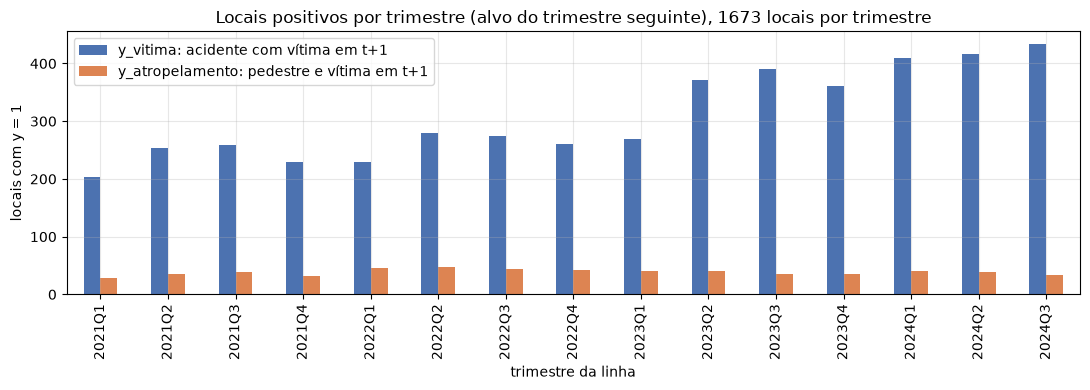

In [9]:
fig, ax = plt.subplots(figsize=(11, 4))
modelagem[["y_vitima_positivos", "y_atropelamento_positivos"]].plot.bar(ax=ax, color=["#4c72b0", "#dd8452"])
ax.set(title=f"Locais positivos por trimestre (alvo do trimestre seguinte), {features['local_id'].nunique()} locais por trimestre",
       xlabel="trimestre da linha", ylabel="locais com y = 1")
ax.legend(["y_vitima: acidente com vítima em t+1", "y_atropelamento: pedestre e vítima em t+1"])
plt.tight_layout()
periodos = {"treino": ("2021Q1", "2022Q4"), "validacao": ("2023Q1", "2023Q4"), "teste": ("2024Q1", "2024Q3")}
pd.DataFrame({p: {alvo: modelagem.loc[i:f, f"{alvo}_prevalencia"].mean().round(3)
                  for alvo in ["y_vitima", "y_atropelamento"]} for p, (i, f) in periodos.items()})

**Interpretação.** O alvo primário (`y_vitima`) tem de 204 a 434 locais positivos por
trimestre: prevalência de 12–17% no treino, subindo para 22–26% a partir de 2023Q2, reflexo de um
registro mais completo nos anos recentes. A subida entre treino e teste é uma mudança de
distribuição que a validação temporal expõe e que a validação aleatória esconderia.

O alvo secundário (`y_atropelamento`, o tema do Projeto 6) tem só **28 a 48 positivos por
trimestre** (1,7–2,9%). São cerca de 310 positivos em todo o treino, para dezenas de colunas
depois do one-hot. A regra usual de pelo menos 10 eventos por variável não se sustenta, e um
PR-AUC medido sobre 30 a 40 positivos por trimestre varia muito de um trimestre para o outro.
Os dois alvos são treinados e avaliados, mas o atropelamento continua **secundário**; a
decisão está no `ARCHITECTURE.md`, seção 17.2.

## 7. Visualizações

### 7.1 Volume de chamados por ano

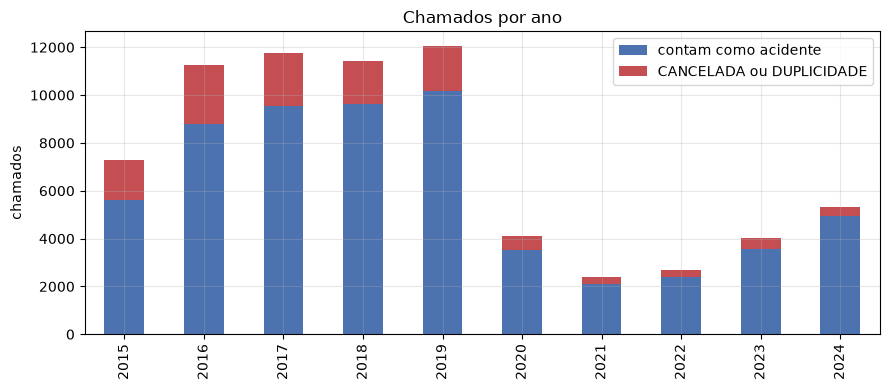

In [10]:
fig, ax = plt.subplots()
contagem = sinistros.groupby(["ano_arquivo", sinistros["situacao"].isin(["CANCELADA", "DUPLICIDADE"])]).size().unstack()
contagem.columns = ["contam como acidente", "CANCELADA ou DUPLICIDADE"]
contagem.plot.bar(stacked=True, ax=ax, color=["#4c72b0", "#c44e52"])
ax.set(title="Chamados por ano", xlabel="", ylabel="chamados")
plt.tight_layout()

O volume cai de cerca de 11–12 mil chamados por ano (2016–2019) para 2–5 mil a partir de 2020,
e os chamados cancelados somem junto. A queda é do **registro**, não necessariamente dos
sinistros (ressalva 5 do README gerado na limpeza): é a mesma quebra da seção 5 vista em
volume. Por isso as features trazem a participação relativa ao lado da contagem absoluta.

### 7.2 Acidentes por local: cauda longa

4290 locais; 1807 com ≥ 3 acidentes na série inteira
grade (≥ 3 acidentes até 2022Q4, fim do treino): 1673 locais, que somam 94% dos acidentes de 2015–2024


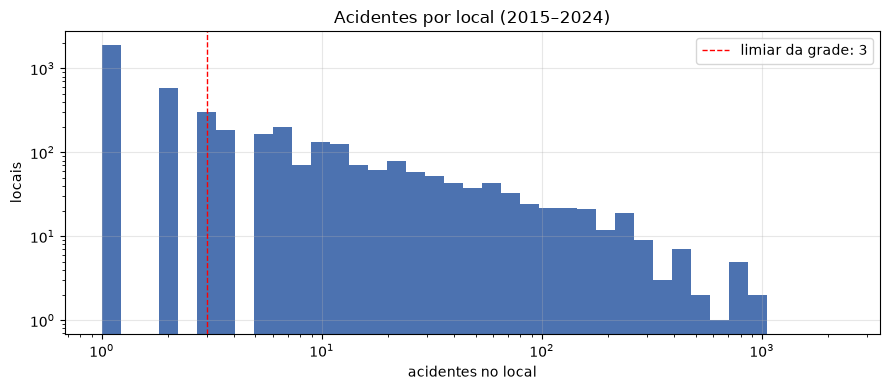

In [11]:
por_local = acidentes["local_id"].value_counts()
fig, ax = plt.subplots()
ax.hist(por_local, bins=np.logspace(0, np.log10(por_local.max()), 40), color="#4c72b0")
ax.set(xscale="log", yscale="log", title="Acidentes por local (2015–2024)", xlabel="acidentes no local", ylabel="locais")
ax.axvline(3, color="red", ls="--", lw=1, label="limiar da grade: 3")
ax.legend()
plt.tight_layout()
ate_treino = acidentes.loc[acidentes["trimestre"] <= "2022Q4", "local_id"].value_counts()
grade = ate_treino.index[ate_treino >= 3]
print(f"{len(por_local)} locais; {(por_local >= 3).sum()} com ≥ 3 acidentes na série inteira")
print(f"grade (≥ 3 acidentes até 2022Q4, fim do treino): {len(grade)} locais, "
      f"que somam {por_local[grade].sum() / por_local.sum():.0%} dos acidentes de 2015–2024")

A distribuição é de cauda longa: metade dos 4.290 locais tem no máximo 2 acidentes em dez anos,
e poucas avenidas (Mascarenhas de Moraes, Caxangá, Agamenon) somam milhares. O limiar de
**≥ 3 acidentes** descarta a massa de locais com um ou dois registros, que inflaria a classe
negativa sem informação. A contagem usa **só os acidentes até 2022Q4**, o fim do treino: contar a
série inteira poria na grade locais que só passaram a ter acidentes em 2023–2024, ou seja, a
grade seria escolhida olhando validação e teste (`ARCHITECTURE.md`, seção 17.7). Com o corte, a
grade tem 1.673 locais (seriam 1.807 contando a série inteira), que somam 94% dos acidentes.

### 7.3 Perfil horário e dia da semana

linhas sem hora: 4.1% (quase todas de 2022)


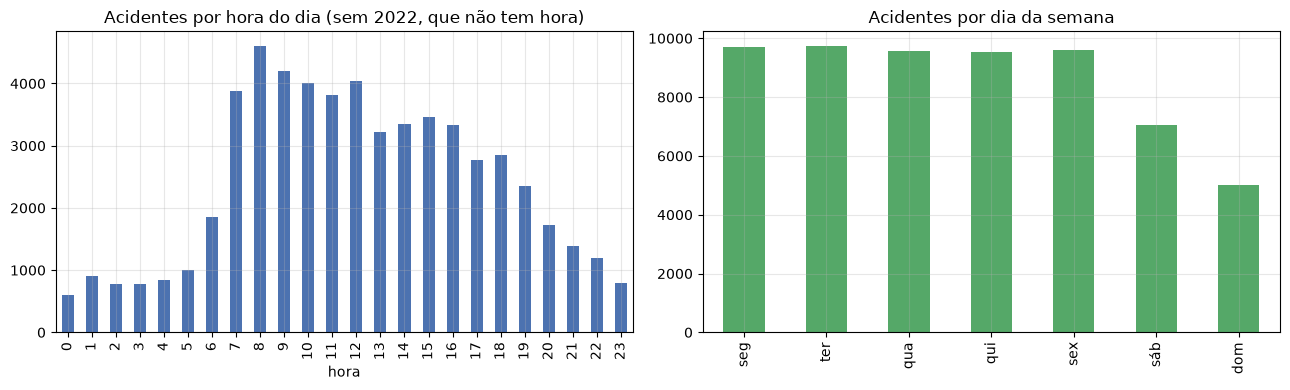

In [12]:
com_hora = acidentes.dropna(subset=["hora"])
hora = com_hora["hora"].str[:2].astype(int)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
hora.value_counts().sort_index().plot.bar(ax=a1, color="#4c72b0")
a1.set(title="Acidentes por hora do dia (sem 2022, que não tem hora)", xlabel="hora")
dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
acidentes["data"].dt.day_of_week.value_counts().sort_index().set_axis(dias).plot.bar(ax=a2, color="#55a868")
a2.set(title="Acidentes por dia da semana")
plt.tight_layout()
print(f"linhas sem hora: {acidentes['hora'].isna().mean():.1%} (quase todas de 2022)")

Os acidentes se concentram entre 7h e 19h, com picos nos horários de deslocamento, e caem de
madrugada; o fim de semana tem menos acidentes por dia que os dias úteis. Como `hora` está
vazia em 2022, a faixa horária **não** entra na chave do local (seção 3.1): vira o perfil
horário histórico do local (frações de madrugada, manhã, tarde e noite), calculado só com as
linhas que têm hora, com a flag `hora_indisponivel` onde não há nenhuma.

### 7.4 Bairros com mais acidentes com vítima (2021–2024)

93 bairros; os 20 maiores somam 64%


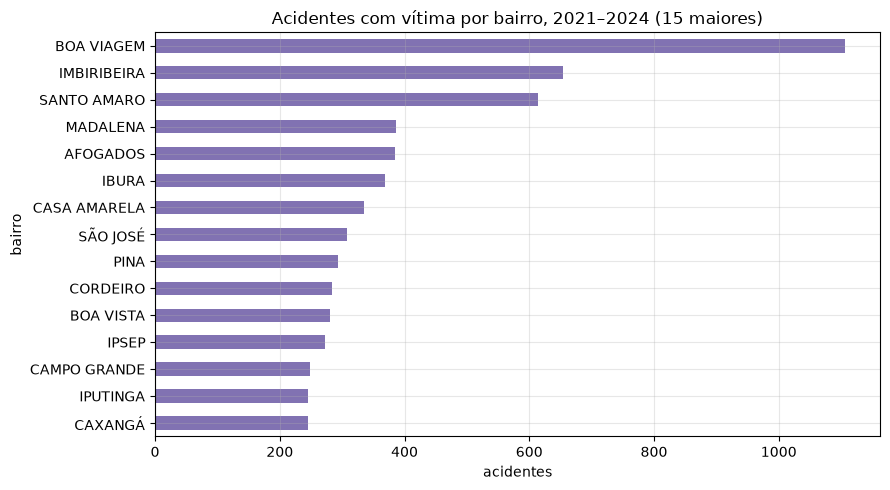

In [13]:
recentes = acidentes[(acidentes["data"].dt.year >= 2021) & acidentes["com_vitima"]]
fig, ax = plt.subplots(figsize=(9, 5))
recentes["bairro"].value_counts().head(15).iloc[::-1].plot.barh(ax=ax, color="#8172b2")
ax.set(title="Acidentes com vítima por bairro, 2021–2024 (15 maiores)", xlabel="acidentes")
plt.tight_layout()
print(f"{recentes['bairro'].nunique()} bairros; os 20 maiores somam {recentes['bairro'].value_counts().head(20).sum() / len(recentes):.0%}")

Poucos bairros concentram os acidentes com vítima: Boa Viagem, Imbiribeira e os bairros
cortados pelas grandes avenidas (Caxangá, Agamenon) lideram. Isso sustenta duas features: o
bairro como categórica, com one-hot nos 20 mais frequentes e `OUTROS` no resto (93 bairros
seriam colunas demais para o volume de positivos), e os acidentes do bairro no trimestre, que
mede o "clima" de risco em volta do local.

### 7.5 Preenchimento das colunas de contexto por ano

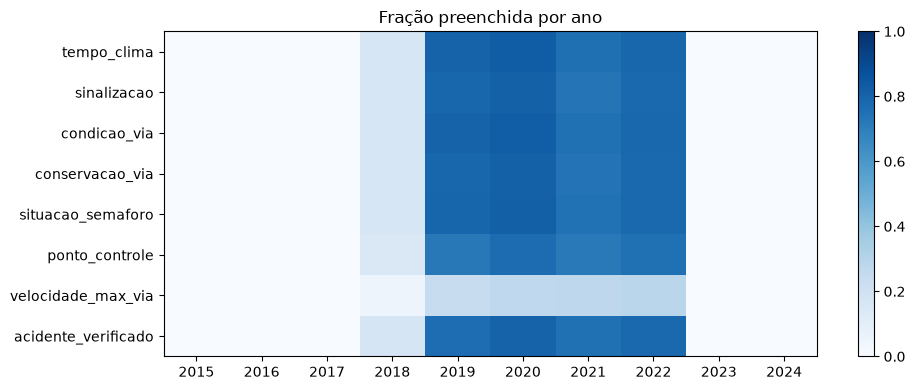

In [14]:
contexto = ["tempo_clima", "sinalizacao", "condicao_via", "conservacao_via", "situacao_semaforo",
            "ponto_controle", "velocidade_max_via", "acidente_verificado"]
preenchido = sinistros[contexto].notna()
preenchido["acidente_verificado"] = sinistros["acidente_verificado"].ne("DESCONHECIDO")
mapa = preenchido.groupby(sinistros["ano_arquivo"]).mean().T
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(mapa.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set(xticks=range(mapa.shape[1]), xticklabels=mapa.columns, yticks=range(mapa.shape[0]), yticklabels=mapa.index,
       title="Fração preenchida por ano")
ax.grid(False)
plt.colorbar(im, ax=ax)
plt.tight_layout()

As colunas de condição da via só existem de fato entre 2018 e 2022; em 2023–2024 a coluna
existe mas vem vazia. Para o modelo, isso significa que as features de via são o **último
valor conhecido** no local (e não o do trimestre), e que a ausência é informativa: um local
sem nenhum registro de via vira `DESCONHECIDO`, e não a moda de outro local. É a justificativa
do tratamento de categóricas da seção 3.4.

### 7.6 Tipos de acidente e atropelamentos

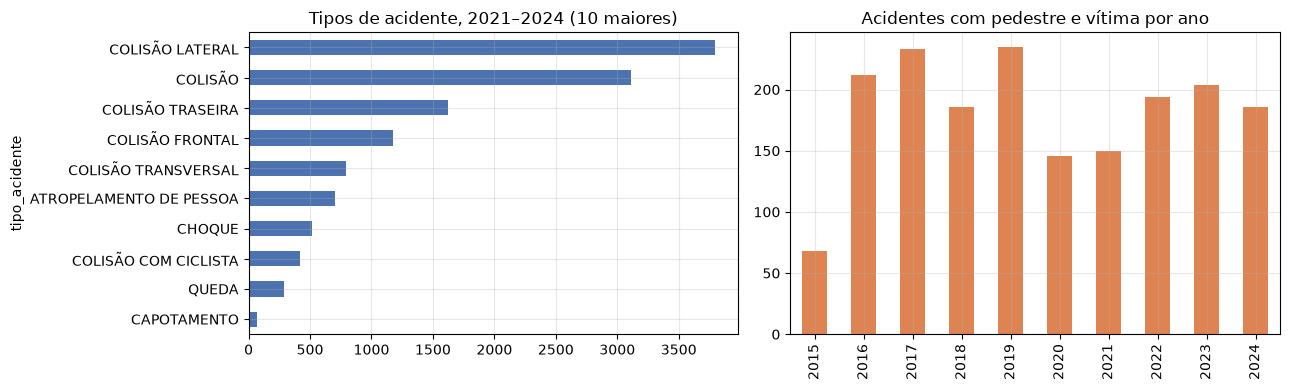

In [15]:
recentes_todos = acidentes[acidentes["data"].dt.year >= 2021]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
recentes_todos["tipo_acidente"].value_counts().head(10).iloc[::-1].plot.barh(ax=a1, color="#4c72b0")
a1.set(title="Tipos de acidente, 2021–2024 (10 maiores)")
atrop = acidentes.assign(atropelamento_vitima=(acidentes["pedestre"].fillna(0) > 0) & acidentes["com_vitima"])
atrop.groupby(atrop["data"].dt.year)["atropelamento_vitima"].sum().plot.bar(ax=a2, color="#dd8452")
a2.set(title="Acidentes com pedestre e vítima por ano", xlabel="")
plt.tight_layout()

Colisões e quedas de moto dominam os tipos; o atropelamento com vítima (pedestre envolvido e
alguém ferido) é ordens de grandeza mais raro, com 150 a 250 casos por ano na cidade inteira
desde 2020. É a mesma escassez que limita o alvo secundário: o tema do Projeto 6 é relevante,
mas a base não tem eventos suficientes para que ele seja o alvo principal de um modelo por
local e trimestre.

## 8. Decisões de tratamento (seção 3.4) e por quê

- **Nulos numéricos → mediana do treino.** As contagens e médias por local são assimétricas
  (cauda longa, seção 7.2); a mediana não é puxada pelos poucos locais extremos. Ela é calculada
  só no treino, dentro do `Pipeline` (há teste para isso).
- **Nulos categóricos → `DESCONHECIDO`.** O nulo vem de mudança de formulário (seções 3 e 7.5),
  não de esquecimento aleatório; tratá-lo como categoria preserva essa informação em vez de
  inventar um valor.
- **Encoding.** One-hot com `handle_unknown` seguro; `bairro` nos 20 mais frequentes + `OUTROS`;
  `sentido_via` (92 valores) e `situacao_placa` (29) também agrupam as categorias raras.
- **Normalização.** `StandardScaler` nas numéricas, obrigatório para KNN, MLP e Regressão Logística.
- **Desbalanceamento.** Prevalência de 12–25% (`y_vitima`) e 2% (`y_atropelamento`):
  `class_weight='balanced'` onde o modelo aceita. Sem SMOTE: interpolar locais sintéticos num
  painel temporal criaria trimestres que não existiram.
- **Duplicados.** Os 2 exatos saem na limpeza; `CANCELADA` e `DUPLICIDADE` ficam como coluna e
  fora das contagens.

## 9. Ressalvas documentadas

1. A coluna `timestamp` do dicionário do portal não existe; o nome real é `data` (`DATA` em 2018–2019).
2. `endereco_cruzamento`, `numero_cruzamento` e `referencia_cruzamento` só existem de 2016 a 2019:
   viram feature (`tem_cruzamento_registrado`, nº de vias transversais), nunca chave do local.
3. `hora` está vazia em todo o CSV de 2022 e não é recuperável (Tarefa 0): `data` não tem horário
   e nenhuma outra coluna traz a hora.
4. `acidente_verificado` só existe de 2018 em diante: não é filtro, é categórica com `DESCONHECIDO`.
5. Até 2020 a fonte deixa vazia a célula de contagem que vale zero; a limpeza trata vazio como 0.
6. 2015 só tem dados a partir de junho; são **chamados** da CTTU, que podem divergir dos relatórios oficiais.
7. Chamados `CANCELADA` (11.563) e `DUPLICIDADE` (455) e 32 linhas datadas de dez/2025 ficam fora das contagens.
8. A grade (≥ 3 acidentes) conta só acidentes até 2022Q4; locais que só ganham histórico depois disso
   ficam fora até o período de treino andar (seção 7.2).
9. **Leave-One-Out não se aplica:** são dezenas de milhares de linhas (LOO exigiria um ajuste por
   linha), e, como o k-fold, ele treinaria com trimestres futuros. A validação é temporal (notebook 02).